# IA para Cibersegurança — Aula 10 (em sala)
## Ataques adversariais em imagens: enganando o modelo que VOCÊS treinaram

**Dupla:** `Paulo Eduardo`  ·  `André Coelho`

> Esta é uma aula **mão na massa**. Rodem as células **na ordem**. Onde houver **🧪 Atividade**, parem, façam e **✏️ anotem** a resposta (vão para o relatório).

Na **Aula 2** vocês treinaram um classificador de imagens no **Teachable Machine** e salvaram o modelo (`modelo_aula2.h5`). Hoje vocês vão **atacá-lo** e, principalmente, **medir** o ataque com as métricas que vimos nos slides.

**Dois ataques:**
- **FGSM** — um único passo na direção que mais confunde o modelo.
- **PGD** — vários passos pequenos; mais eficaz com perturbação menor.

**As três perguntas que todo ataque responde (o tripé):**
- **Imperceptibilidade** — o quanto a imagem mudou? (L∞, L2, L0)
- **Efetividade** — enganou? com quanta confiança?
- **Custo** — quantos passos/consultas custou?

> É o início do arco **atacar → defender**: na próxima aula, deixamos o modelo mais robusto.

## 1. Importações (rode primeiro)

O modelo do Teachable Machine foi exportado com o **Keras 2**. No Colab novo o padrão é o **Keras 3**, que **não consegue carregar** esse modelo. A célula abaixo instala o **Keras 2 legado (`tf-keras`)** e o ativa **antes** de importar o TensorFlow.

⚠️ **Se você já rodou alguma célula**, reinicie o ambiente uma vez (*Ambiente de execução → Reiniciar sessão*) e rode a partir daqui — a troca de Keras só funciona se for feita antes de importar o TensorFlow.

In [3]:
# IMPORTANTE: estas linhas precisam rodar ANTES de importar o TensorFlow.
!pip install -q tf-keras
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"   # usa o Keras 2 (necessario para o modelo do Teachable Machine)

import numpy as np
from PIL import Image, ImageOps
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['figure.figsize'] = (8, 8)
mpl.rcParams['axes.grid'] = False

import tensorflow as tf
import pandas as pd

import tf_keras
print('TensorFlow', tf.__version__, '| Keras (legado) via tf-keras', tf_keras.__version__)

TensorFlow 2.21.0 | Keras (legado) via tf-keras 2.21.0


## 2. Funções úteis
As mesmas funções dos notebooks anteriores (pré-processamento 224×224, intervalo [-1, 1], exibição e classificação) **mais** uma função para comparar imagens lado a lado.

In [4]:
# Pré-processa a imagem para o formato que o modelo espera
def preprocess(image):
    image = tf.cast(image, tf.float32)
    image = tf.image.resize(image, (224, 224))
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)  # -> [-1, 1]
    image = image[None, ...]
    return image

# Carrega e pré-processa uma imagem do disco
def loadAndPreprocessImage(image_path):
    image = Image.open(image_path).convert('RGB')
    return preprocess(image)

# Exibe a imagem (e, se houver, a classe/confiança e o epsilon)
def printImage(image, class_name=None, confidence_score=None, eps=None):
    plt.figure()
    plt.imshow(image[0] * 0.5 + 0.5)   # de [-1,1] para [0,1]
    if (class_name is None) and (eps is not None):
        plt.title('Epsilon: {:0.3f}'.format(eps))
    elif (class_name is not None) and (eps is None):
        plt.title('Classe: {}  Confiança: {:.2f}'.format(class_name, confidence_score))
    elif (class_name is not None) and (eps is not None):
        plt.title('Epsilon: {:0.3f}\nClasse: {}  Confiança: {:.2f}'.format(eps, class_name, confidence_score))
    plt.axis('off'); plt.show()

# Classifica uma amostra e devolve (probabilidades, classe, confiança)
def classifySample(image, pretrained_model):
    image_probs = pretrained_model.predict(image, verbose=0)
    index = int(np.argmax(image_probs))
    class_name = decode_predictions[index].strip()
    confidence_score = float(image_probs[0][index])
    return image_probs, class_name, confidence_score

### Comparação lado a lado
Função que mostra, de uma vez: **original | adversarial | perturbação** (amplificada para ficar visível). Vamos usar bastante.

In [5]:
def mostrar_comparacao(original, adv, titulo=''):
    delta = adv - original
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(original[0] * 0.5 + 0.5); ax[0].set_title('Original'); ax[0].axis('off')
    ax[1].imshow(adv[0] * 0.5 + 0.5);      ax[1].set_title('Adversarial'); ax[1].axis('off')
    d = delta[0].numpy()
    d = (d - d.min()) / (d.max() - d.min() + 1e-9)   # normaliza só para visualizar
    ax[2].imshow(d); ax[2].set_title('Perturbação (amplificada)'); ax[2].axis('off')
    if titulo: fig.suptitle(titulo, fontsize=14)
    plt.tight_layout(); plt.show()

## 3. Carregar o modelo de vocês (Aula 2)

Apontem para o modelo treinado no Teachable Machine. Duas opções:
- **Google Drive** (se salvaram lá na Aula 2): montem o Drive e usem o caminho.
- **Upload**: subam `modelo_aula2.h5` (ou `keras_model.h5`) e `labels_aula2.txt` (ou `labels.txt`) pelo painel de arquivos do Colab.

In [8]:
# (Opcional) Montar o Drive, se o modelo estiver salvo lá
from google.colab import drive
drive.mount('/content/drive')

PROJETO = '/content/drive/MyDrive/ia-ciberseguranca'   # ajuste se necessário
MODELO  = PROJETO + '/models/modelo_aula2.h5'
LABELS  = PROJETO + '/models/labels_aula2.txt'

# Se preferir upload direto, comente as 3 linhas acima e use:
# PROJETO = '.'
# MODELO, LABELS = 'keras_model.h5', 'labels.txt'

Mounted at /content/drive


In [9]:
# --- Ajuste para carregar modelos do Teachable Machine em versoes novas do Keras ---
# O TM exporta DepthwiseConv2D com o argumento 'groups', que o Keras novo nao aceita.
# Esta subclasse ignora esse argumento na hora de carregar.
import tensorflow as tf
from tensorflow.keras.layers import DepthwiseConv2D as _DepthwiseConv2D

class DepthwiseConv2D(_DepthwiseConv2D):
    def __init__(self, *args, **kwargs):
        kwargs.pop('groups', None)
        super().__init__(*args, **kwargs)

# Carrega o classificador e os rotulos
pretrained_model = tf.keras.models.load_model(
    MODELO, compile=False,
    custom_objects={'DepthwiseConv2D': DepthwiseConv2D}
)
pretrained_model.trainable = False

decode_predictions = open(LABELS, 'r').readlines()
class_names = [l.strip().split(' ', 1)[-1] for l in decode_predictions if l.strip()]
print('Classes:', class_names)

Classes: ['apple', 'banana', 'orange']


## 4. Imagem de teste e classificação original (baseline)

Carreguem **uma imagem de teste** de uma classe que o modelo reconhece bem. Essa será a imagem atacada.

Previsão original: apple | confiança: 0.991


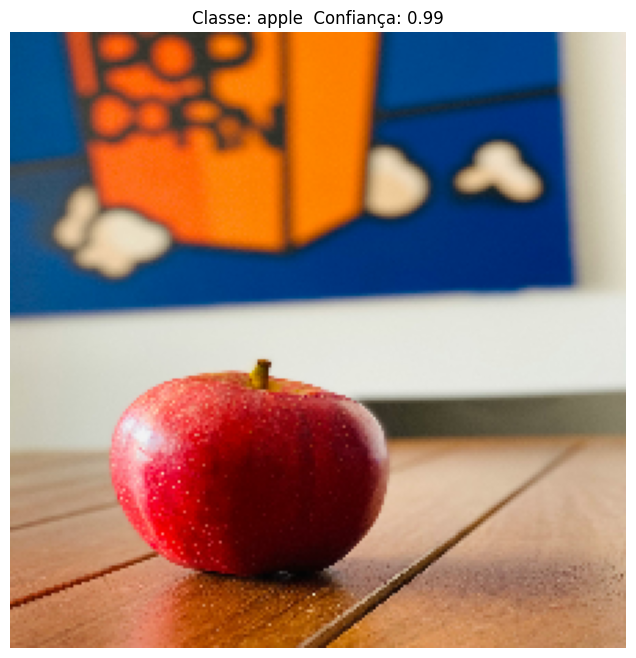

In [10]:
# Ajuste o caminho para uma imagem de teste sua
CAMINHO_IMG = PROJETO + '/data/test/apple/chris-dez-t2ZIt-WNXrk-unsplash.jpg'   # ou faça upload e use 'exemplo.png'

image1 = loadAndPreprocessImage(CAMINHO_IMG)

image_probs, class_name, confidence_score = classifySample(image1, pretrained_model)
true_index = int(np.argmax(image_probs))
print('Previsão original:', class_name, '| confiança:', round(confidence_score, 3))
printImage(image1, class_name, confidence_score)

### Para qual classe a IA quase foi? (top-2)
Ver o **2º palpite** ajuda a entender para onde o ataque vai empurrar a decisão.

In [11]:
def top2(image, model):
    probs = model.predict(image, verbose=0)[0]
    ordem = np.argsort(probs)[::-1]
    return [(class_names[i], float(probs[i])) for i in ordem[:2]]

for nome, prob in top2(image1, pretrained_model):
    print(f'{nome:>20}: {prob:.3f}')

               apple: 0.991
              orange: 0.009


## 5. As métricas de hoje (o tripé)

Antes de atacar, preparamos as funções que **medem** o ataque. São elas que vocês vão reportar.

- **Imperceptibilidade** — olhamos a perturbação `δ = adversarial − original`:
  - **L∞** = a maior mudança em um único pixel (o "teto" — é o que o ε controla);
  - **L2** = a energia total da perturbação;
  - **L0** = a fração de pixels que mudaram.
- **Efetividade** — a previsão **virou**? a **confiança** subiu no erro?
- **Custo** — quantos **passos** o ataque usou (FGSM = 1; PGD = nº de iterações).

In [12]:
def metricas_imperceptibilidade(original, adv):
    delta = (adv - original).numpy().ravel()
    linf = float(np.max(np.abs(delta)))          # maior mudança em um pixel
    l2   = float(np.sqrt(np.sum(delta**2)))      # energia total
    l0   = float(np.mean(np.abs(delta) > 1e-6))  # fração de pixels alterados
    return linf, l2, l0

def avaliar_ataque(original, adv, model, idx_verdadeiro, n_passos):
    _, _, conf0 = classifySample(original, model)
    probs1, c1, conf1 = classifySample(adv, model)
    virou = int(np.argmax(probs1)) != idx_verdadeiro
    linf, l2, l0 = metricas_imperceptibilidade(original, adv)
    return {
        'classe_original':    class_names[idx_verdadeiro],
        'classe_apos_ataque': c1,
        'virou?':             'SIM' if virou else 'nao',
        'conf_antes':         round(conf0, 3),
        'conf_depois':        round(conf1, 3),
        'Linf':               round(linf, 3),
        'L2':                 round(l2, 2),
        'L0_%pixels':         round(l0 * 100, 1),
        'passos':             n_passos,
    }

def painel(m):
    print('-' * 52)
    print(f"IMPERCEPTIBILIDADE   L8={m['Linf']}   L2={m['L2']}   L0={m['L0_%pixels']}% dos pixels")
    print(f"EFETIVIDADE          virou? {m['virou?']}  |  confianca {m['conf_antes']} -> {m['conf_depois']}")
    print(f"                     {m['classe_original']}  ->  {m['classe_apos_ataque']}")
    print(f"CUSTO                {m['passos']} passo(s)")
    print('-' * 52)

## Parte A — FGSM (Fast Gradient Sign Method)

**A ideia, sem fórmula:** o modelo tem uma "noção" de quanto erra (a *loss*). O gradiente aponta a **direção que mais aumenta esse erro**. O FGSM dá **um passo** nessa direção, mexendo cada pixel só um pouquinho (controlado por **epsilon**).

In [13]:
# Perturbação FGSM: sinal do gradiente da loss em relação à imagem de entrada
def create_adversarial_perturbation_FGSM(input_image, input_label, pretrained_model):
    loss_object = tf.keras.losses.CategoricalCrossentropy()
    input_image = tf.convert_to_tensor(input_image)
    with tf.GradientTape() as tape:
        tape.watch(input_image)
        prediction = pretrained_model(input_image)
        loss = loss_object(input_label, prediction)
    gradient = tape.gradient(loss, input_image)
    signed_grad = tf.sign(gradient)      # só a direção (+1/-1) por pixel
    return signed_grad

# Soma a perturbação à imagem original, para vários epsilons, mantendo tudo em [-1, 1]
def construct_adversarial_samples(clean_sample, adversarial_perturbation, eps):
    adversarial_samples = []
    for e in eps:
        adv = clean_sample + e * adversarial_perturbation
        adv = tf.clip_by_value(adv, -1, 1)
        adversarial_samples.append(adv)
    return adversarial_samples

### Rótulo da imagem
Usamos como alvo do ataque a **classe que o modelo prevê hoje** — o objetivo é empurrar a decisão para LONGE dela (ataque **sem alvo**).

In [14]:
label = tf.one_hot(true_index, image_probs.shape[-1])
label = tf.reshape(label, (1, image_probs.shape[-1]))
print('Classe atacada:', class_names[true_index])

Classe atacada: apple


### Gerando a perturbação e visualizando

Mapa de perturbação (o "chuviscado" que será somado):


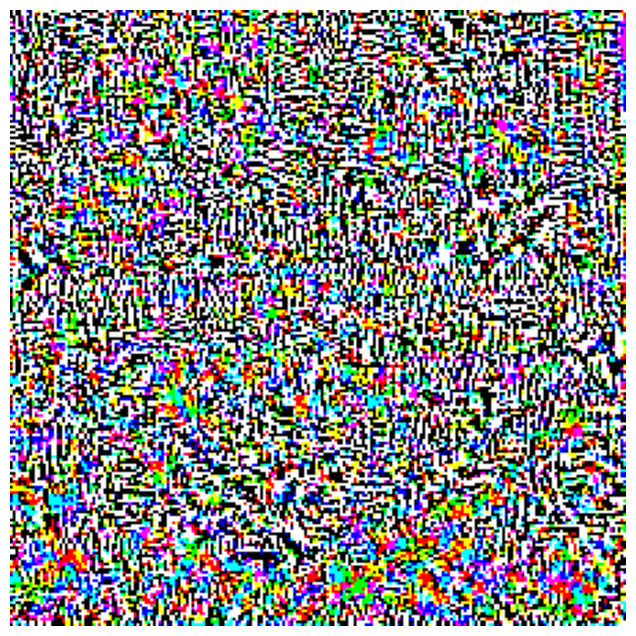

In [15]:
adversarial_perturbation = create_adversarial_perturbation_FGSM(image1, label, pretrained_model)
print('Mapa de perturbação (o "chuviscado" que será somado):')
printImage(adversarial_perturbation)

### Varredura de epsilon
Rodem e observem: conforme o epsilon cresce, a **confiança cai** e, em algum ponto, a **previsão vira**.

epsilon=   0  ->  apple  (conf 0.99)


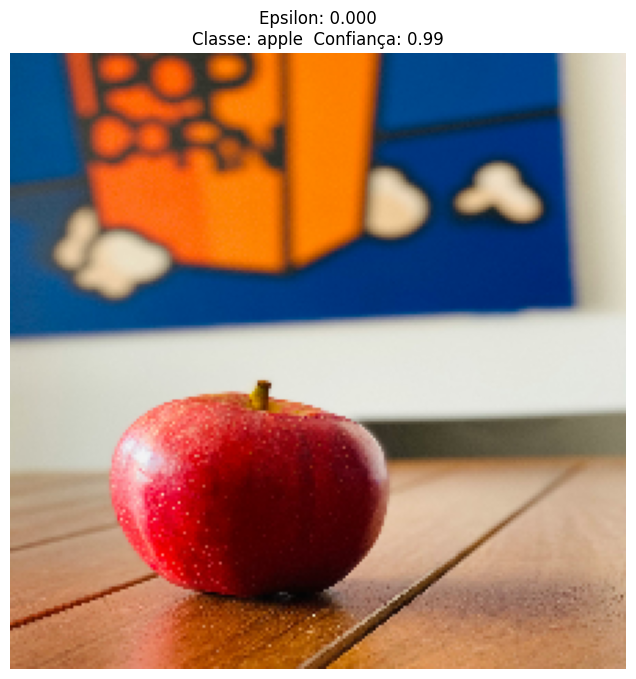

epsilon=0.01  ->  orange  (conf 0.99)  <-- VIROU!


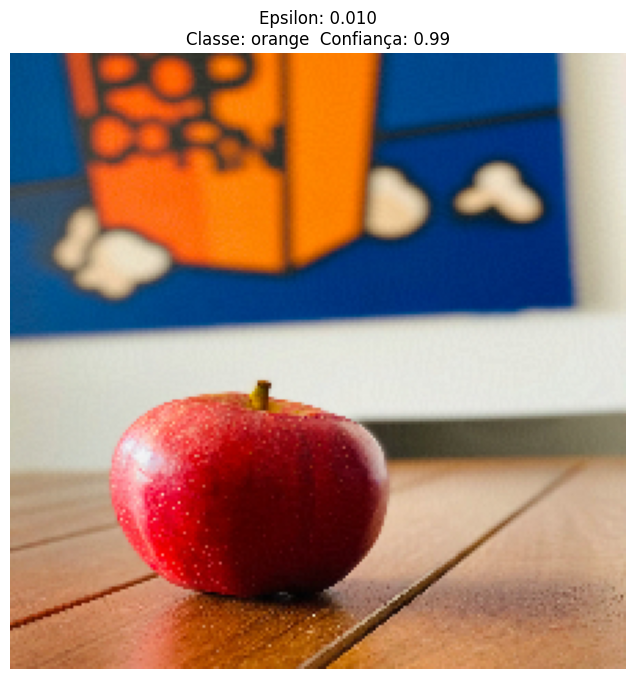

epsilon=0.05  ->  orange  (conf 0.98)  <-- VIROU!


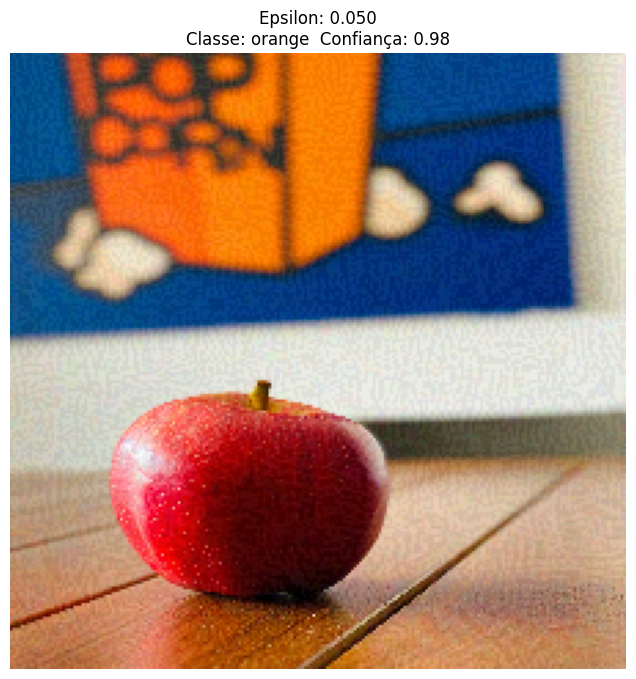

epsilon= 0.1  ->  orange  (conf 0.94)  <-- VIROU!


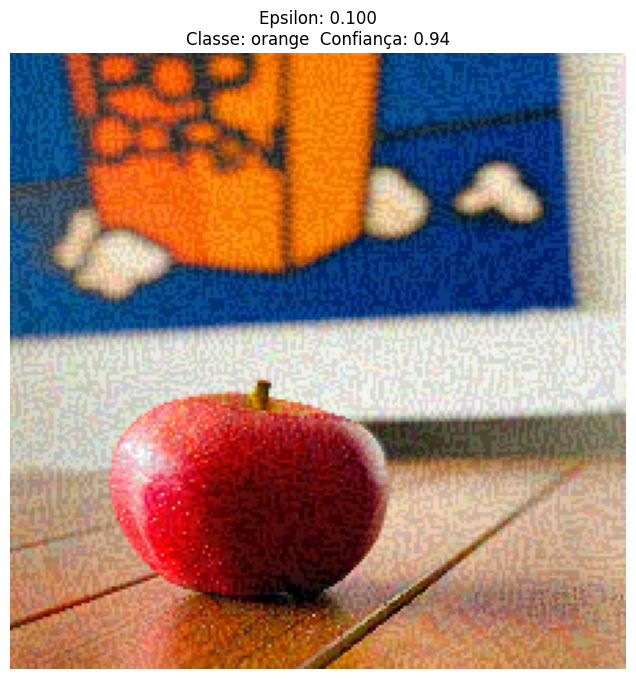

epsilon=0.15  ->  orange  (conf 0.85)  <-- VIROU!


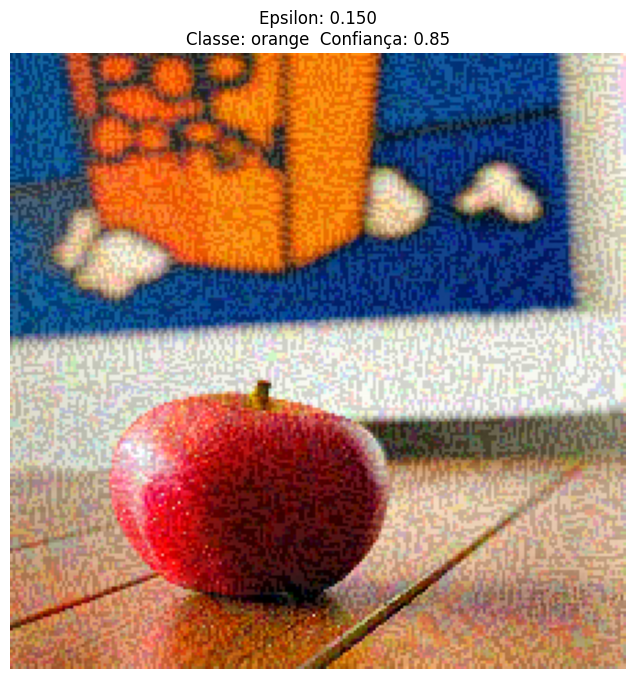

In [16]:
epsilons = [0, 0.01, 0.05, 0.10, 0.15]
adversarial_samples = construct_adversarial_samples(image1, adversarial_perturbation, epsilons)

for i, adv in enumerate(adversarial_samples):
    _, cname, conf = classifySample(adv, pretrained_model)
    virou = '  <-- VIROU!' if cname != class_names[true_index] else ''
    print(f'epsilon={epsilons[i]:>4}  ->  {cname}  (conf {conf:.2f}){virou}')
    printImage(adv, class_name=cname, confidence_score=conf, eps=epsilons[i])

### 🧪 Atividade 1 — Qual é o **epsilon crítico** do SEU modelo?
O epsilon crítico é o **menor ε que faz a previsão virar**. Rodem a célula abaixo (podem afinar a lista `grade`).

**✏️ Anotem:** o epsilon crítico e se, nesse ponto, a imagem **já parecia** alterada a olho nu.

Epsilon critico (FGSM): 0.005


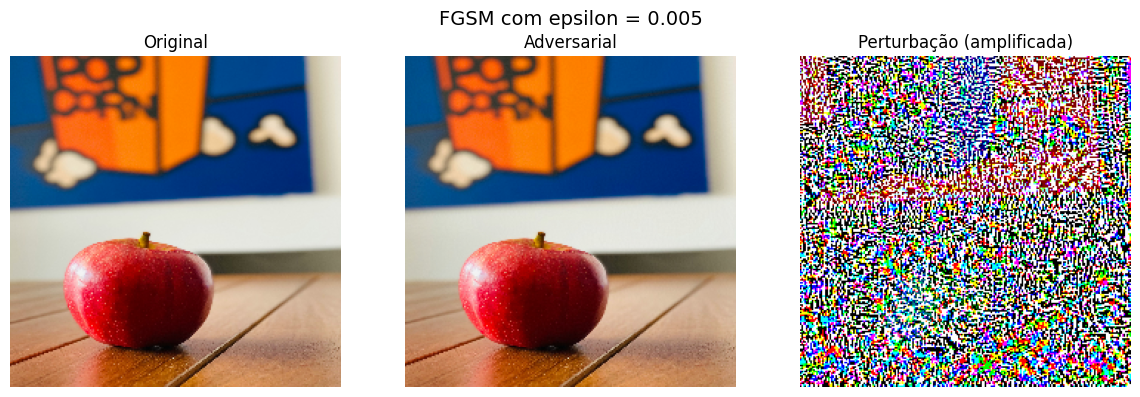

In [17]:
def epsilon_critico(image, label, model, idx, perturbacao, grade):
    for e in grade:
        adv = tf.clip_by_value(image + e * perturbacao, -1, 1)
        pred = int(np.argmax(model.predict(adv, verbose=0)))
        if pred != idx:
            return e, adv
    return None, None

grade = [0.0, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20]
eps_crit, adv_fgsm = epsilon_critico(image1, label, pretrained_model, true_index, adversarial_perturbation, grade)

if eps_crit is None:
    print('Nao virou ate epsilon =', grade[-1], '- aumente a grade.')
    EPS_FGSM = grade[-1]
    adv_fgsm = tf.clip_by_value(image1 + EPS_FGSM * adversarial_perturbation, -1, 1)
else:
    EPS_FGSM = eps_crit
    print('Epsilon critico (FGSM):', EPS_FGSM)

mostrar_comparacao(image1, adv_fgsm, titulo=f'FGSM com epsilon = {EPS_FGSM}')

### 🧪 Atividade 2 — Medir o ataque FGSM (o tripé)
Agora rodem o **painel de métricas** no ataque FGSM do epsilon crítico.

**✏️ Anotem:** L∞, L2, L0, se virou e a confiança antes/depois.

In [18]:
m_fgsm = avaliar_ataque(image1, adv_fgsm, pretrained_model, true_index, n_passos=1)
painel(m_fgsm)

----------------------------------------------------
IMPERCEPTIBILIDADE   L8=0.005   L2=1.9   L0=96.2% dos pixels
EFETIVIDADE          virou? SIM  |  confianca 0.991 -> 0.924
                     apple  ->  orange
CUSTO                1 passo(s)
----------------------------------------------------


## Parte B — PGD (Projected Gradient Descent)

O FGSM dá **um** passo grande. O PGD dá **vários passos pequenos** (tamanho `alpha`) e, depois de cada passo, "puxa de volta" a imagem para dentro de uma caixinha de raio `eps` ao redor da original (a *projeção*). Costuma enganar com perturbação **menor e mais eficaz**.

In [19]:
def pgd_attack(image, label, model, eps=0.03, alpha=0.005, n_iters=20):
    loss_object = tf.keras.losses.CategoricalCrossentropy()
    original = tf.convert_to_tensor(image)
    adv = tf.identity(original)
    for _ in range(n_iters):
        adv = tf.convert_to_tensor(adv)
        with tf.GradientTape() as tape:
            tape.watch(adv)
            pred = model(adv)
            loss = loss_object(label, pred)
        grad = tape.gradient(loss, adv)
        adv = adv + alpha * tf.sign(grad)                      # passo pequeno na direcao do erro
        adv = tf.clip_by_value(adv, original - eps, original + eps)   # projeta na caixa de raio eps
        adv = tf.clip_by_value(adv, -1, 1)                     # mantem imagem valida
    return adv

Depois do PGD -> classe: orange | confianca: 1.0


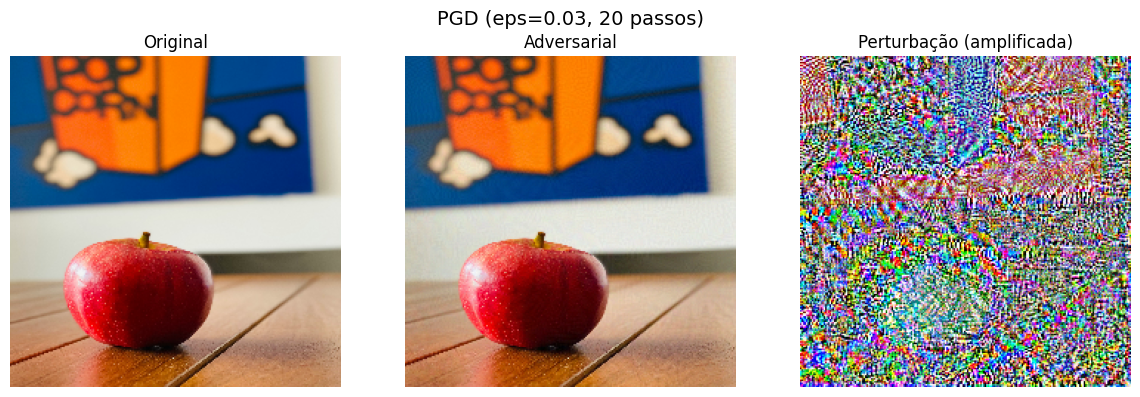

In [20]:
N_ITERS = 20
adv_pgd = pgd_attack(image1, label, pretrained_model, eps=0.03, alpha=0.005, n_iters=N_ITERS)

_, cname, conf = classifySample(adv_pgd, pretrained_model)
print('Depois do PGD -> classe:', cname, '| confianca:', round(conf, 3))
mostrar_comparacao(image1, adv_pgd, titulo='PGD (eps=0.03, 20 passos)')

### 🧪 Atividade 3 — FGSM × PGD lado a lado
Vamos medir os dois **no mesmo** orçamento `eps=0.03` e comparar numa tabela.

**✏️ Anotem:** qual precisou de **menos perturbação** (L∞/L2) para virar a classe?

In [21]:
# FGSM com o mesmo orcamento do PGD (eps=0.03), para comparar de forma justa
adv_fgsm_003 = tf.clip_by_value(image1 + 0.03 * adversarial_perturbation, -1, 1)

tabela = pd.DataFrame([
    {'ataque': 'FGSM (1 passo)', **avaliar_ataque(image1, adv_fgsm_003, pretrained_model, true_index, 1)},
    {'ataque': 'PGD (20 passos)', **avaliar_ataque(image1, adv_pgd,       pretrained_model, true_index, N_ITERS)},
])
tabela

,ataque,classe_original,classe_apos_ataque,virou?,conf_antes,conf_depois,Linf,L2,L0_%pixels,passos
0,FGSM (1 passo),apple,orange,SIM,0.991,0.994,0.03,11.26,96.2,1
1,PGD (20 passos),apple,orange,SIM,0.991,1.000,0.03,7.58,85.5,20


## Parte C — Curva de robustez (acurácia × epsilon)

Até agora atacamos UMA imagem. Vamos medir o estrago no **conjunto de teste**, comparando **FGSM e PGD**: para cada epsilon, qual a acurácia do modelo sob ataque?

> Dica de sala: se estiver lento, use poucas imagens por classe no `data/test`.

In [22]:
import glob, os

# Monta uma lista (imagem, indice verdadeiro) a partir das pastas data/test/<classe>
TEST_DIR = PROJETO + '/data/test'
amostras = []
for ci, classe in enumerate(class_names):
    for arq in glob.glob(f'{TEST_DIR}/{classe}/*'):
        if arq.lower().endswith(('.png', '.jpg', '.jpeg')):
            amostras.append((loadAndPreprocessImage(arq), ci))
print('Imagens de teste carregadas:', len(amostras))

Imagens de teste carregadas: 15


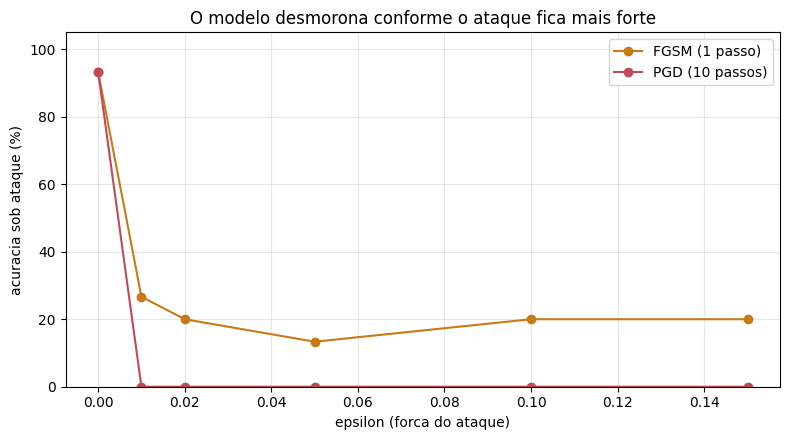

epsilon |  FGSM  |  PGD
     0  |   93% |   93%
  0.01  |   27% |    0%
  0.02  |   20% |    0%
  0.05  |   13% |    0%
   0.1  |   20% |    0%
  0.15  |   20% |    0%


In [23]:
def acuracia_sob_ataque_fgsm(amostras, model, eps):
    acertos = 0
    for img, idx in amostras:
        label = tf.reshape(tf.one_hot(idx, len(class_names)), (1, len(class_names)))
        pert = create_adversarial_perturbation_FGSM(img, label, model)
        adv = tf.clip_by_value(img + eps * pert, -1, 1)
        pred = int(np.argmax(model.predict(adv, verbose=0)))
        acertos += int(pred == idx)
    return acertos / max(len(amostras), 1)

def acuracia_sob_ataque_pgd(amostras, model, eps, alpha=0.005, n_iters=10):
    acertos = 0
    for img, idx in amostras:
        label = tf.reshape(tf.one_hot(idx, len(class_names)), (1, len(class_names)))
        adv = pgd_attack(img, label, model, eps=eps, alpha=alpha, n_iters=n_iters)
        pred = int(np.argmax(model.predict(adv, verbose=0)))
        acertos += int(pred == idx)
    return acertos / max(len(amostras), 1)

eps_grid = [0, 0.01, 0.02, 0.05, 0.10, 0.15]
acc_fgsm = [acuracia_sob_ataque_fgsm(amostras, pretrained_model, e) for e in eps_grid]
acc_pgd  = [acuracia_sob_ataque_pgd(amostras, pretrained_model, e) for e in eps_grid]

plt.figure(figsize=(8, 4.5))
plt.plot(eps_grid, [a*100 for a in acc_fgsm], 'o-', color='#C97A16', label='FGSM (1 passo)')
plt.plot(eps_grid, [a*100 for a in acc_pgd],  'o-', color='#C1495B', label='PGD (10 passos)')
plt.xlabel('epsilon (forca do ataque)'); plt.ylabel('acuracia sob ataque (%)')
plt.title('O modelo desmorona conforme o ataque fica mais forte')
plt.ylim(0, 105); plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

print('epsilon |  FGSM  |  PGD')
for e, af, ap in zip(eps_grid, acc_fgsm, acc_pgd):
    print(f'{e:>6}  | {af:>5.0%} | {ap:>5.0%}')

### 🧪 Atividade 4 — Ler a curva e medir a queda
**✏️ Anotem (vai para o relatório):**
- Acurácia **sem ataque** (epsilon 0): ________
- Acurácia **mínima** sob ataque: ________  (em qual epsilon? ____)
- **Queda** = sem ataque − mínima: ________ pontos percentuais
- Qual curva cai mais rápido, FGSM ou PGD? Por quê?

In [24]:
base = acc_fgsm[0] * 100
min_fgsm = min(acc_fgsm) * 100
min_pgd  = min(acc_pgd) * 100
print(f'Acuracia sem ataque:        {base:.0f}%')
print(f'Minima sob FGSM:            {min_fgsm:.0f}%   (queda de {base - min_fgsm:.0f} p.p.)')
print(f'Minima sob PGD:             {min_pgd:.0f}%   (queda de {base - min_pgd:.0f} p.p.)')
print(f'\nTaxa de sucesso ~ quanto a acuracia caiu (quanto maior, mais efetivo o ataque).')

Acuracia sem ataque:        93%
Minima sob FGSM:            13%   (queda de 80 p.p.)
Minima sob PGD:             0%   (queda de 93 p.p.)

Taxa de sucesso ~ quanto a acuracia caiu (quanto maior, mais efetivo o ataque).


## Parte D — 🧪 Atividade 5 (desafio): ataque **com alvo** (targeted)

Até aqui o ataque era "faça errar qualquer coisa". No **com alvo**, escolhemos a classe que queremos que o modelo diga — e **descemos** a loss dessa classe (`adv = img − eps·sinal(grad)`).

**✏️ Escolham** uma `CLASSE_ALVO` diferente da original e vejam se conseguem forçar o modelo a prevê-la.

Alvo desejado: banana  |  modelo previu: orange (conf 0.88)
Ainda nao - tente aumentar o epsilon.


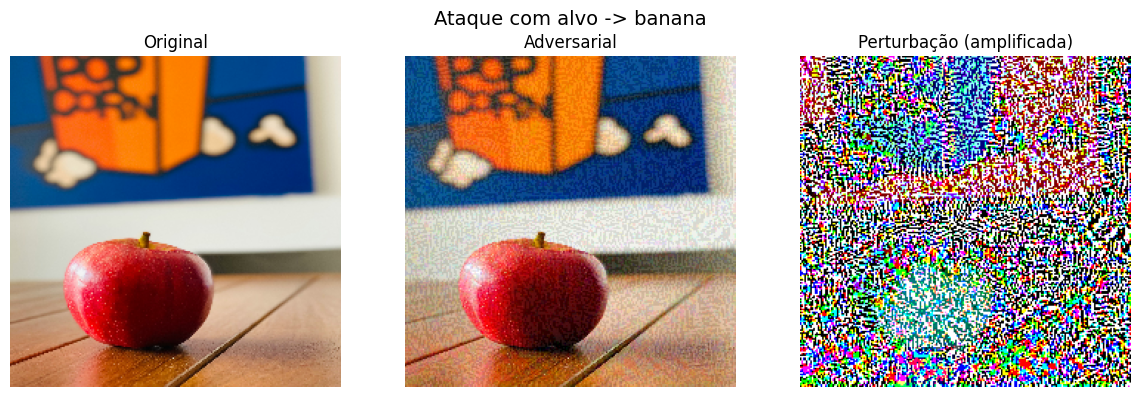

In [25]:
def fgsm_direcionado(image, target_label, model, eps):
    loss_object = tf.keras.losses.CategoricalCrossentropy()
    image = tf.convert_to_tensor(image)
    with tf.GradientTape() as tape:
        tape.watch(image)
        pred = model(image)
        loss = loss_object(target_label, pred)
    grad = tape.gradient(loss, image)
    adv = image - eps * tf.sign(grad)          # DESCER a loss do alvo
    return tf.clip_by_value(adv, -1, 1)

# TODO: escolham uma classe-alvo (precisa ser diferente da original)
CLASSE_ALVO = class_names[(true_index + 1) % len(class_names)]
alvo_idx = class_names.index(CLASSE_ALVO)
alvo_label = tf.reshape(tf.one_hot(alvo_idx, len(class_names)), (1, len(class_names)))

adv_alvo = fgsm_direcionado(image1, alvo_label, pretrained_model, eps=0.10)
_, c_alvo, conf_alvo = classifySample(adv_alvo, pretrained_model)
print(f'Alvo desejado: {CLASSE_ALVO}  |  modelo previu: {c_alvo} (conf {conf_alvo:.2f})')
print('Sucesso!' if c_alvo == CLASSE_ALVO else 'Ainda nao - tente aumentar o epsilon.')
mostrar_comparacao(image1, adv_alvo, titulo=f'Ataque com alvo -> {CLASSE_ALVO}')

## Tabela final de métricas (para o relatório)
Rodem para consolidar tudo numa tabela só. **Copiem para o relatório do ataque de evasão.**

In [26]:
linhas = [
    {'ataque': 'FGSM (eps critico)', **avaliar_ataque(image1, adv_fgsm, pretrained_model, true_index, 1)},
    {'ataque': 'PGD (20 passos)',    **avaliar_ataque(image1, adv_pgd,  pretrained_model, true_index, N_ITERS)},
]
try:
    linhas.append({'ataque': f'Targeted -> {CLASSE_ALVO}', **avaliar_ataque(image1, adv_alvo, pretrained_model, true_index, 1)})
except NameError:
    pass

resumo = pd.DataFrame(linhas)
print('Acuracia (conjunto de teste): sem ataque {:.0f}% | min FGSM {:.0f}% | min PGD {:.0f}%'.format(
    acc_fgsm[0]*100, min(acc_fgsm)*100, min(acc_pgd)*100))
resumo

Acuracia (conjunto de teste): sem ataque 93% | min FGSM 13% | min PGD 0%


,ataque,classe_original,classe_apos_ataque,virou?,conf_antes,conf_depois,Linf,L2,L0_%pixels,passos
0,FGSM (eps critico),apple,orange,SIM,0.991,0.924,0.005,1.90,96.2,1
1,PGD (20 passos),apple,orange,SIM,0.991,1.000,0.030,7.58,85.5,20
2,Targeted -> banana,apple,orange,SIM,0.991,0.877,0.100,37.22,96.2,1


## Discussão (respondam no notebook)
1) A partir de qual epsilon o SEU modelo começou a errar? A imagem já parecia alterada nesse ponto?

O epsilon crítico do FGSM foi 0,005, o menor valor da grade em que a previsão virou de apple para orange. Na varredura, com ε = 0,01 o modelo já previa orange com 99% de confiança. Como as imagens estão na escala [-1, 1], 0,005 corresponde a cerca de 0,6 nível de cinza em 255. Por isso, a olho nu, a imagem não parecia alterada. Só a perturbação amplificada mostra o “chuviscado”. Vale conferir isso na figura do notebook antes de entregar.

2) FGSM × PGD: qual precisou de **menos perturbação** (L∞/L2) para virar a classe? Por quê?

**FGSM × PGD: qual precisou de menos perturbação (L∞/L2) para virar a classe? Por quê?**

No mesmo orçamento (ε = 0,03), os dois viraram a classe e têm o mesmo L∞ (0,03). A diferença aparece no L2 e no L0:

| Ataque | L∞ | L2 | L0 (% de pixels alterados) | Confiança em *orange* |
|---|---|---|---|---|
| FGSM (1 passo) | 0,03 | 11,26 | 96,2% | 0,994 |
| PGD (20 passos) | 0,03 | 7,58 | 85,5% | 1,000 |

O PGD usou cerca de 33% menos energia (L2) e mexeu em menos pixels. A curva de robustez mostra o mesmo padrão:

- Em ε = 0,01, a acurácia caiu de 93% para 27% sob FGSM e para 0% sob PGD.
- A acurácia mínima foi 13% sob FGSM e 0% sob PGD, ou seja, quedas de 80 e 93 pontos percentuais.

**Por quê?** O FGSM faz um único passo, assumindo que a loss é aproximadamente linear, e como usa só o sinal do gradiente empurra todos os pixels com a força máxima. O PGD dá passos pequenos e recalcula o gradiente a cada um, então acompanha a curvatura real da loss. Depois, a projeção mantém a perturbação dentro da caixa de raio ε.

**Ressalva:** o FGSM com o ε crítico (0,005) teve L∞ = 0,005 e L2 = 1,90, menos que o PGD fixado em 0,03. Isso acontece porque não buscamos o menor ε do PGD. Só a comparação no mesmo ε e a curva de acurácia mostram a vantagem do PGD. Outro sinal de que o FGSM é mais "grosseiro" é que sua acurácia não cai de forma monótona (27%, 20%, 13% e depois volta a 20% quando ε aumenta).

3) Olhando o **tripé** (imperceptibilidade × custo × efetividade), qual ataque você usaria se fosse o atacante? E se fosse o defensor avaliando o pior caso?

Como atacante, eu usaria o PGD. O custo extra é pequeno (20 passos, contra 1), e ele é mais efetivo e menos perceptível: derruba a acurácia a 0% com ε = 0,01 e deixa a confiança do erro em 1,0. O FGSM só compensaria se o atacante precisasse de velocidade ou tivesse pouquíssimas consultas. Os dois são ataques white-box, pois usam o gradiente do modelo. Um atacante sem acesso ao modelo precisaria de outra abordagem.

Como defensor avaliando o pior caso, eu também usaria o PGD. Se o modelo só resiste ao FGSM, a robustez é aparente. A acurácia sob PGD é um limite mais realista do que o modelo aguenta.

4) Em que situação real isso seria perigoso para um sistema de visão (ex.: a câmera da Aula 9)?

Seria perigoso em sistemas de visão que tomam decisões automáticas com base na classificação:

- controle de acesso por reconhecimento facial;
- câmeras de vigilância que deveriam detectar pessoas ou objetos;
- veículos autônomos lendo placas e sinais;
- triagem de imagens médicas;
- moderação de conteúdo.

No caso da câmera da Aula 9, um atacante poderia fazer o sistema classificar errado de forma silenciosa, com alta confiança e sem nenhum alerta. Aqui o ataque foi digital, com acesso direto aos pixels. No mundo físico ele é mais difícil, mas existem ataques por adesivos ou óculos impressos. Além disso, o nosso modelo tem só 3 classes, e a orange parece ser o “destino fácil” do ataque. A tentativa com alvo (banana) falhou: o modelo previu orange, com confiança 0,88.

5) Que ideias vocês têm para **defender** o modelo desse tipo de ataque?

- Treino adversarial: incluir exemplos gerados por PGD no treino. É o assunto da próxima aula e a defesa mais estabelecida.
- Avaliar sempre sob PGD e acompanhar a curva acurácia × ε, não só a acurácia limpa (93%).
- Pré-processamento da entrada: compressão JPEG, suavização ou redução de bits, que tiram parte do ruído fino. Elas ajudam, mas costumam ser contornadas por ataques adaptativos.
- Mais dados e augmentation com ruído e variações. Nosso conjunto de teste tem só 15 imagens, então qualquer métrica é frágil.
- Detecção e monitoramento: sinalizar entradas suspeitas, por exemplo com confiança alta mas inconsistente com outros modelos ou sensores. Um ensemble de modelos também dificulta o ataque.
- Reduzir a exposição: limitar consultas e não devolver probabilidades detalhadas. Isso atrapalha ataques black-box, mas não protege contra quem tem o modelo.
- Revisão humana nas decisões críticas.

## Checklist do entregável de hoje
- [x] Modelo do Teachable Machine (Aula 2) carregado
- [x] Classificação original (baseline) registrada
- [x] FGSM aplicado + **epsilon crítico** encontrado
- [x] **Métricas do tripé** medidas (L∞, L2, L0, confiança, custo)
- [x] PGD aplicado e comparado ao FGSM (tabela)
- [x] Curva de acurácia × epsilon (FGSM e PGD) + **queda medida**
- [ ] Ataque com alvo (desafio)
- [ ] Respostas da discussão
- [ ] **Tabela final de métricas** colada no relatório

**Próxima aula:** defesas — como deixar o modelo mais robusto (treino adversarial) e medir se funcionou.